# Multimodal Ask-Based Evaluation Agent on GCP
This notebook implements an **Ask-Based Vision Agent** powered by Google GenAI's latest model family.

### Architecture Overview:
1. **Agent Orchestration**: **Gemini 3.5 Flash** (`gemini-3.5-flash`) parses natural language queries, classifies intent, enriches generative prompts, and dynamically selects image metrics.
2. **Image Generation**: Powered by **Nano Banana 2** (`gemini-3.1-flash-image`) or **Nano Banana Pro** (`gemini-3-pro-image`) image generation engines.
3. **VLM Evaluation (VLM-as-a-Judge)**: **Gemini 3.5 Flash** analyzes the resulting image using custom **Pydantic Response Schemas** to deliver clean, structured metric evaluations.

### GCP Compatibility:
The notebook uses the standard `google-genai` Python library, making it highly secure and fully compatible with **Vertex AI Workbench** or **Vertex AI Colab Enterprise** on GCP.

In [ ]:
# Install Google GenAI SDK and image utilities
%pip install --upgrade --quiet google-genai pillow pydantic

In [ ]:
# Fix: Reinstall Pillow and restart runtime to clear the import cache
!pip install --force-reinstall --upgrade pillow

import os

# Automatically restart the kernel to pick up the new Pillow installation
#if not os.environ.get('RESTARTED'):
#    os.environ['RESTARTED'] = '1'
#    import IPython
#    IPython.Application.instance().kernel.do_shutdown(True)

import io
import json
from typing import List, Optional
from PIL import Image, ImageDraw
from pydantic import BaseModel, Field
from google import genai
from google.genai import types
from IPython.display import display, Markdown

# GCP/Colab Authentication
try:
    from google.colab import auth
    auth.authenticate_user()
    print("GCP User Authenticated Successfully.")
except ImportError:
    print("Not running in Google Colab. Ensure local Application Default Credentials (ADC) are configured.")

# Initialize client
client = genai.Client(enterprise=True)
print("Vertex AI Agent Client Initialized.")

  Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.9 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 12.3.0
    Uninstalling pillow-12.3.0:
      Successfully uninstalled pillow-12.3.0


GCP User Authenticated Successfully.
Vertex AI Agent Client Initialized.


In [ ]:
from pydantic import BaseModel, Field
from typing import List, Optional

# 1. Define Structured Output Schema for VLM Evaluations
class MetricEvaluation(BaseModel):
    metric_name: str = Field(description="Name of the evaluated metric (e.g., 'Prompt Adherence', 'Aesthetic Quality', 'OCR & Text Spelling', 'Anatomy Integrity')")
    score: int = Field(description="Assigned score from 1 (poor) to 10 (perfect)")
    reasoning: str = Field(description="Step-by-step physical and aesthetic analysis justifying the score")

class ImageEvaluationReport(BaseModel):
    overall_summary: str = Field(description="Concise summary highlighting overall layout quality, strengths, and flaws")
    evaluations: List[MetricEvaluation] = Field(description="List of evaluation metrics with individual scores")
    improvement_suggestions: List[str] = Field(description="Actionable suggestions to improve prompt structure, text legibility, or scene realism")

# 2. Define Action Schema for the Agent Brain's Orchestration Plan
class AgentAction(BaseModel):
    intent: str = Field(description="Resolved intent: 'GENERATE_AND_EVALUATE' (create and critique), 'EVALUATE_ONLY' (critique user image), or 'GENERAL_CHAT'")
    generation_prompt: Optional[str] = Field(None, description="Refined text prompt for image generation. Automatically enriches sparse prompts with style, lighting, and composition.")
    model_choice: str = Field("gemini-3-pro-image", description="Model selection: 'gemini-3.1-flash-image' (Nano Banana 2) or 'gemini-3-pro-image' (Nano Banana Pro)")
    evaluation_metrics: List[str] = Field(default=["Prompt Adherence", "Aesthetic Quality"], description="The critical evaluation metrics to apply based on the request")
    conversational_response: Optional[str] = Field(None, description="Standard chat response if user requested chat or help rather than evaluation")

In [ ]:
from google import genai
from google.genai import types
import json
import io
from PIL import Image
from typing import List, Optional
from IPython.display import display, Markdown

class ImageEvaluationAgent:
    def __init__(self, client: genai.Client):
        self.client = client
        # Updated to gemini-3.5-flash as requested
        self.vlm_model = "gemini-3.5-flash"

    def _plan_action(self, user_query: str, has_image: bool) -> AgentAction:
        """Uses Gemini to plan execution routing and metrics choice."""
        system_instruction = (
            "You are an autonomous orchestrator for an Image Evaluation Agent on GCP.\n"
            "Review the user's query and note whether they uploaded an image.\n"
            "Select relevant evaluation metrics based on the user's instructions."
        )

        response = self.client.models.generate_content(
            model=self.vlm_model,
            contents=f"Query: '{user_query}'\nHas Attached Image: {has_image}",
            config=types.GenerateContentConfig(
                system_instruction=system_instruction,
                response_mime_type="application/json",
                response_schema=AgentAction,
                temperature=0.2
            )
        )
        return AgentAction(**json.loads(response.text))

    def generate_image(self, prompt: str, model_id: str) -> Image.Image:
        """Generates an image via the Gemini visual generation backbone."""
        print(f"[Gen] Constructing visual with: {model_id}...")

        response = self.client.models.generate_content(
            model=model_id,
            contents=[prompt],
            config=types.GenerateContentConfig(
                response_modalities=["IMAGE"],
                image_config=types.ImageConfig(aspect_ratio="1:1", image_size="1K")
            )
        )

        for part in response.candidates[0].content.parts:
            if part.inline_data:
                return Image.open(io.BytesIO(part.inline_data.data))
        raise ValueError("Image generation returned zero pixel data.")

    def evaluate_image(self, image: Image.Image, metrics: List[str], target_prompt: Optional[str] = None) -> ImageEvaluationReport:
        """Executes structured evaluation on the image."""
        img_bytes_io = io.BytesIO()
        image.save(img_bytes_io, format="PNG")
        image_part = types.Part.from_bytes(data=img_bytes_io.getvalue(), mime_type="image/png")

        prompt = f"Analyze this image objectively across the following criteria: {metrics}."

        response = self.client.models.generate_content(
            model=self.vlm_model,
            contents=[image_part, prompt],
            config=types.GenerateContentConfig(
                response_mime_type="application/json",
                response_schema=ImageEvaluationReport,
                temperature=0.1
            )
        )
        return ImageEvaluationReport(**json.loads(response.text))

    def ask(self, query: str, user_image: Optional[Image.Image] = None):
        has_image = user_image is not None
        plan = self._plan_action(query, has_image)

        display(Markdown(f"### Agent Execution Blueprint"))
        print(f"- Intent: {plan.intent}")

        active_image = user_image
        if plan.intent == "GENERATE_AND_EVALUATE":
            active_image = self.generate_image(plan.generation_prompt or query, plan.model_choice)
            display(active_image)

        if active_image:
            report = self.evaluate_image(active_image, plan.evaluation_metrics, plan.generation_prompt)
            display(Markdown(f"### Critic's Report"))
            display(Markdown(f"**Overall Synthesis:** {report.overall_summary}"))
            return active_image, report
        return None, None

## Execution Loop 1: End-to-End Dynamic Image Generation & Metric Evaluation
In this test, the Agent uses **Nano Banana Pro** to handle precise text rendering of the brand name `'LUCID DREAM'` and uses **Gemini 3.5 Flash** to critique its OCR spelling accuracy.

### Agent Execution Blueprint

- Intent: GENERATE_AND_EVALUATE
[Gen] Constructing visual with: gemini-3-pro-image...


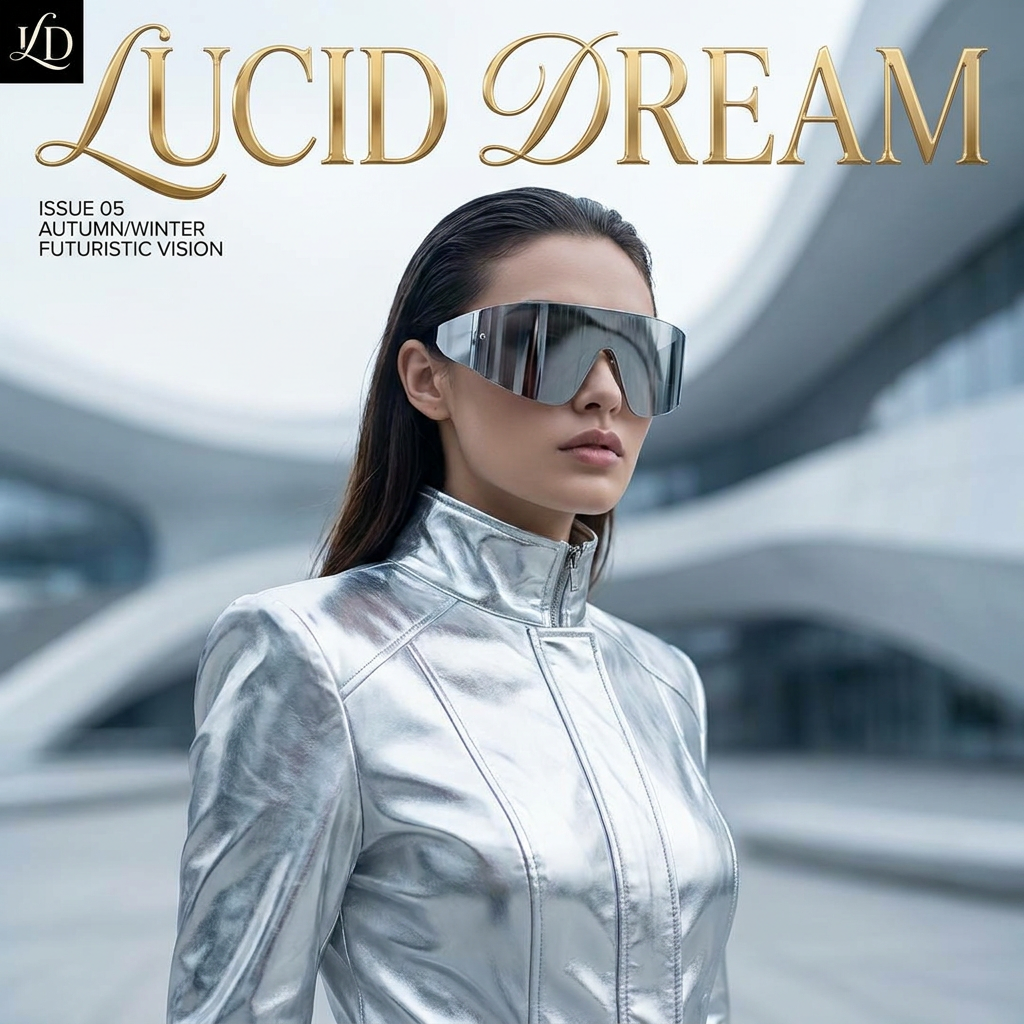

### Critic's Report

**Overall Synthesis:** An exceptionally well-crafted magazine cover that perfectly captures a futuristic aesthetic. The composition, color harmony, and typography are highly professional, with flawless text rendering and a cohesive sci-fi fashion theme.

In [ ]:
# Ensure the client is initialized (in case cell DbNVZMqXRoLX wasn't re-run after restart)
from google import genai
try:
    client
except NameError:
    client = genai.Client(enterprise=True)

agent = ImageEvaluationAgent(client)

request_query = (
    "Generate a high-fashion magazine cover layout featuring a woman wearing large metallic sunglasses, "
    "with the header text: 'LUCID DREAM' in elegant serif typeface. "
    "Use Nano Banana Pro to render the text precisely, "
    "and evaluate spelling accuracy, aesthetic composition, and prompt alignment."
)

image, report = agent.ask(request_query)

## Execution Loop 2: Directly Grading an Uploaded / Local Image
To evaluate layouts or graphic assets directly, you can pass them straight into the agent.

In [ ]:
from PIL import Image, ImageDraw

# Create a mock image with intentional text for testing local VLM metrics evaluation
mock_local_image = Image.new("RGB", (500, 500), color=(18, 18, 24))
draw_tool = ImageDraw.Draw(mock_local_image)
draw_tool.text((120, 240), "SYSTEM OK - VERIFIED", fill=(255, 100, 100))

# Grade local image directly
agent.ask(
    query="Evaluate this provided dashboard diagnostic screen layout for visual contrast and text rendering.",
    user_image=mock_local_image
)

### Agent Execution Blueprint

- Intent: EVALUATE_ONLY


### Critic's Report

**Overall Synthesis:** The image features an extremely minimalist design consisting of a solid dark background and a single line of red text. While the text rendering is flawless and sharp, the visual contrast is relatively low due to the dark red hue against a near-black background.

(<PIL.Image.Image image mode=RGB size=500x500>,
 ImageEvaluationReport(overall_summary='The image features an extremely minimalist design consisting of a solid dark background and a single line of red text. While the text rendering is flawless and sharp, the visual contrast is relatively low due to the dark red hue against a near-black background.', evaluations=[MetricEvaluation(metric_name='Visual Contrast', score=6, reasoning="The contrast between the dark red text ('SYSTEM OK - VERIFIED') and the dark charcoal/black background is low. While legible in a dark environment, it does not meet high-contrast accessibility standards, which may make it difficult to read for some users or under bright ambient lighting."), MetricEvaluation(metric_name='Text Rendering', score=10, reasoning='The text is rendered with perfect digital precision. The font is a clean, modern sans-serif, and there are no compression artifacts, blurring, or spelling errors. Every letter is sharp and clearly defined.')